
# Homework 3 — Model explainability

## 1. Environment and data preparation

I investigate the behavior of my AI-generated text detection models using global and local explainability techniques.

My primary model is a probability-level ensemble combining 60% word-level TF-IDF Logistic Regression and 40% XLM-RoBERTa with head-tail truncation.

I first analyze the saved validation probabilities to understand model agreement, disagreement, and error correction. I then investigate lexical feature importance and local explanations using a memory-efficient interpretable classifier.

I distinguish explanations of the actual ensemble from those of any auxiliary model. I also examine whether apparent author-style signals may instead reflect language or domain differences.

All analyses use the existing training and validation splits, without external datasets or test labels.


In [3]:
import gc
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display
from google.colab import drive
from sklearn.metrics import (
    f1_score,
    classification_report,
    confusion_matrix
)

SEED = 42
CLASS_ORDER = ["human", "ai", "fusion"]

CLASS_COLORS = {
    "human": "#6C3CC8",
    "ai": "#E96BA8",
    "fusion": "#A991E8"
}

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/UCU_AI_HW3")

assert PROJECT_DIR.exists(), "Project directory not found."

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Project directory:", PROJECT_DIR)
print("Environment setup: PASSED")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Python: 3.13.16
NumPy: 2.4.6
Pandas: 2.2.3
Project directory: /content/drive/MyDrive/UCU_AI_HW3
Environment setup: PASSED


In [4]:
TFIDF_PATH = PROJECT_DIR / "tfidf_validation_probs_v1.csv"

XLMR_PATH = (
    PROJECT_DIR / "xlmr_checkpoint2500_validation_probs.csv"
)

assert TFIDF_PATH.exists(), "TF-IDF probabilities not found."
assert XLMR_PATH.exists(), "XLM-R probabilities not found."

tfidf_df = pd.read_csv(TFIDF_PATH, dtype={"id": str})
xlmr_df = pd.read_csv(XLMR_PATH, dtype={"id": str})

assert len(tfidf_df) == len(xlmr_df) == 55_031
assert tfidf_df["id"].is_unique
assert xlmr_df["id"].is_unique

explain_df = tfidf_df.merge(
    xlmr_df,
    on="id",
    how="inner",
    validate="one_to_one",
    suffixes=("_tfidf", "_xlmr")
)

assert len(explain_df) == 55_031

assert (
    explain_df["true_label_tfidf"]
    == explain_df["true_label_xlmr"]
).all()

tfidf_probs = explain_df[
    ["tfidf_human", "tfidf_ai", "tfidf_fusion"]
].to_numpy(dtype=np.float64)

xlmr_probs = explain_df[
    ["headtail_human", "headtail_ai", "headtail_fusion"]
].to_numpy(dtype=np.float64)

ensemble_probs = (
    0.60 * tfidf_probs
    + 0.40 * xlmr_probs
)

for probs in [tfidf_probs, xlmr_probs, ensemble_probs]:
    assert probs.shape == (55_031, 3)
    assert np.isfinite(probs).all()
    assert np.allclose(probs.sum(axis=1), 1.0, atol=1e-4)

y_true = explain_df["true_label_tfidf"].to_numpy()

model_predictions = {
    "TF-IDF": np.asarray(CLASS_ORDER)[
        np.argmax(tfidf_probs, axis=1)
    ],
    "XLM-R head-tail": np.asarray(CLASS_ORDER)[
        np.argmax(xlmr_probs, axis=1)
    ],
    "Ensemble 60/40": np.asarray(CLASS_ORDER)[
        np.argmax(ensemble_probs, axis=1)
    ]
}

print("Restored validation documents:", len(explain_df))

for name, predictions in model_predictions.items():
    score = f1_score(
        y_true,
        predictions,
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )
    print(f"{name}: macro-F1 = {score:.5f}")

print("\nEnsemble restoration: PASSED")

Restored validation documents: 55031
TF-IDF: macro-F1 = 0.87852
XLM-R head-tail: macro-F1 = 0.87345
Ensemble 60/40: macro-F1 = 0.91596

Ensemble restoration: PASSED



## 2. Model agreement and error correction

I analyze how TF-IDF Logistic Regression and XLM-RoBERTa contribute to the final probability ensemble.

I compare their predictions on the fixed validation set and examine agreement, disagreement, and error correction.

In particular, I measure how often the ensemble fixes an incorrect prediction from an individual model, how often it introduces a new error, and which classes benefit most from combining the models.

These analyses explain the complementary behavior of the ensemble, although they do not establish which individual input tokens caused a prediction.


In [5]:
import numpy as np
import pandas as pd
from IPython.display import display

tfidf_pred = model_predictions["TF-IDF"]
xlmr_pred = model_predictions["XLM-R head-tail"]
ensemble_pred = model_predictions["Ensemble 60/40"]

tfidf_correct = tfidf_pred == y_true
xlmr_correct = xlmr_pred == y_true
ensemble_correct = ensemble_pred == y_true

agreement_results = pd.DataFrame({
    "metric": [
        "Both individual models correct",
        "Only TF-IDF correct",
        "Only XLM-R correct",
        "Both individual models incorrect",
        "Models agree on predicted class",
        "Ensemble correct",
        "Ensemble fixes TF-IDF errors",
        "Ensemble fixes XLM-R errors",
        "Ensemble introduces errors vs TF-IDF",
        "Ensemble introduces errors vs XLM-R"
    ],
    "documents": [
        int((tfidf_correct & xlmr_correct).sum()),
        int((tfidf_correct & ~xlmr_correct).sum()),
        int((~tfidf_correct & xlmr_correct).sum()),
        int((~tfidf_correct & ~xlmr_correct).sum()),
        int((tfidf_pred == xlmr_pred).sum()),
        int(ensemble_correct.sum()),
        int((~tfidf_correct & ensemble_correct).sum()),
        int((~xlmr_correct & ensemble_correct).sum()),
        int((tfidf_correct & ~ensemble_correct).sum()),
        int((xlmr_correct & ~ensemble_correct).sum())
    ]
})

agreement_results["share_%"] = (
    agreement_results["documents"]
    / len(y_true) * 100
)

display(agreement_results.round(2))

assert (
    agreement_results.loc[:3, "documents"].sum()
    == len(y_true)
)

print("Agreement and correction analysis: PASSED")

,metric,documents,share_%
0,Both individual models correct,45509,82.70
1,Only TF-IDF correct,3896,7.08
2,Only XLM-R correct,3593,6.53
3,Both individual models incorrect,2033,3.69
4,Models agree on predicted class,47455,86.23
5,Ensemble correct,51168,92.98
6,Ensemble fixes TF-IDF errors,2794,5.08
7,Ensemble fixes XLM-R errors,2872,5.22
8,Ensemble introduces errors vs TF-IDF,1031,1.87
9,Ensemble introduces errors vs XLM-R,806,1.46


Agreement and correction analysis: PASSED


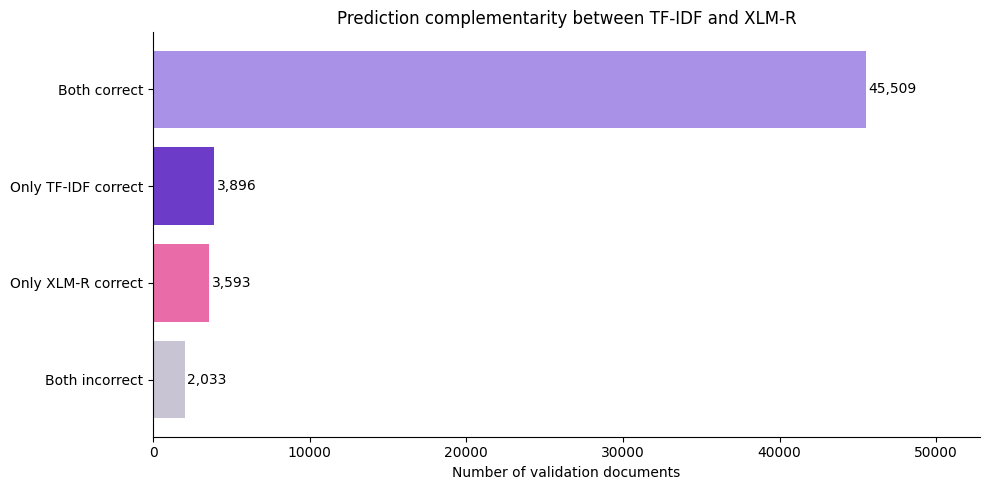

In [6]:
import matplotlib.pyplot as plt

categories = [
    "Both correct",
    "Only TF-IDF correct",
    "Only XLM-R correct",
    "Both incorrect"
]

counts = agreement_results.iloc[:4]["documents"].to_numpy()

colors = [
    "#A991E8",
    "#6C3CC8",
    "#E96BA8",
    "#C9C4D3"
]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    categories[::-1],
    counts[::-1],
    color=colors[::-1]
)

for bar in bars:
    ax.text(
        bar.get_width() + 150,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width()):,}",
        va="center",
        fontsize=10
    )

ax.set_xlim(0, max(counts) * 1.16)
ax.set_xlabel("Number of validation documents")
ax.set_title("Prediction complementarity between TF-IDF and XLM-R")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [7]:
from sklearn.metrics import f1_score

class_results = []

for label in CLASS_ORDER:
    mask = y_true == label

    class_results.append({
        "class": label,
        "documents": int(mask.sum()),
        "tfidf_recall": float(tfidf_correct[mask].mean()),
        "xlmr_recall": float(xlmr_correct[mask].mean()),
        "ensemble_recall": float(ensemble_correct[mask].mean()),
        "fixed_tfidf_errors": int(
            (~tfidf_correct[mask] & ensemble_correct[mask]).sum()
        ),
        "new_errors_vs_tfidf": int(
            (tfidf_correct[mask] & ~ensemble_correct[mask]).sum()
        )
    })

class_correction_df = pd.DataFrame(class_results)

display(class_correction_df.round(4))

print("\nPer-class error correction analysis: PASSED")

,class,documents,tfidf_recall,xlmr_recall,ensemble_recall,fixed_tfidf_errors,new_errors_vs_tfidf
0,human,13529,0.8681,0.8511,0.9097,1066,503
1,ai,24718,0.9911,0.9800,0.9972,170,21
2,fusion,16784,0.7842,0.7962,0.8468,1558,507



Per-class error correction analysis: PASSED



## 3. Local explanations of ensemble decisions

I examine individual validation decisions to understand how the two models contribute to the final ensemble prediction.

For each selected document, I compare class probabilities from TF-IDF, XLM-RoBERTa, and the 60/40 ensemble.

I focus on cases where the ensemble corrects an individual model's error, as well as cases where combining models introduces an error.

These explanations quantify the contributions of the ensemble components. They do not yet identify which input words caused the models' predictions.


In [8]:
import numpy as np
import pandas as pd
from IPython.display import display

tfidf_correct = tfidf_pred == y_true
xlmr_correct = xlmr_pred == y_true
ensemble_correct = ensemble_pred == y_true

case_masks = {
    "Ensemble fixes TF-IDF": (
        ~tfidf_correct & ensemble_correct
    ),
    "Ensemble fixes XLM-R": (
        ~xlmr_correct & ensemble_correct
    ),
    "Ensemble introduces error": (
        tfidf_correct & ~ensemble_correct
    ),
    "Both models incorrect": (
        ~tfidf_correct & ~xlmr_correct
    )
}

selected_cases = []

for case_name, mask in case_masks.items():
    candidate_indices = np.flatnonzero(mask)

    assert len(candidate_indices) > 0, (
        f"No available cases: {case_name}"
    )

    idx = int(candidate_indices[0])

    selected_cases.append({
        "case": case_name,
        "row_index": idx,
        "id": str(explain_df.iloc[idx]["id"]),
        "true_label": y_true[idx],
        "tfidf_prediction": tfidf_pred[idx],
        "xlmr_prediction": xlmr_pred[idx],
        "ensemble_prediction": ensemble_pred[idx]
    })

selected_cases_df = pd.DataFrame(selected_cases)

display(selected_cases_df)

print("Local explanation cases selected: PASSED")

,case,row_index,id,true_label,tfidf_prediction,xlmr_prediction,ensemble_prediction
0,Ensemble fixes TF-IDF,36,768deb,fusion,human,fusion,fusion
1,Ensemble fixes XLM-R,55,ef2c3d,ai,ai,fusion,ai
2,Ensemble introduces error,5,f4c3f0,fusion,fusion,human,human
3,Both models incorrect,25,8c4c79,fusion,human,human,human


Local explanation cases selected: PASSED


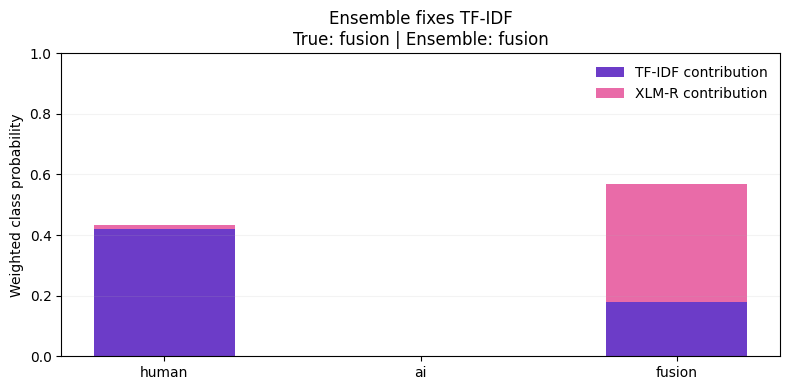

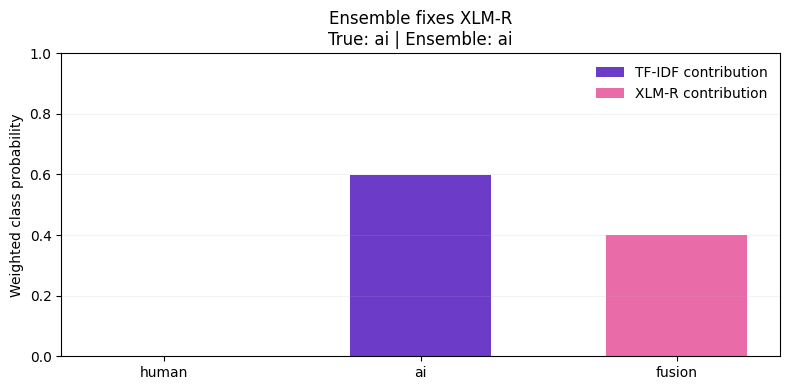

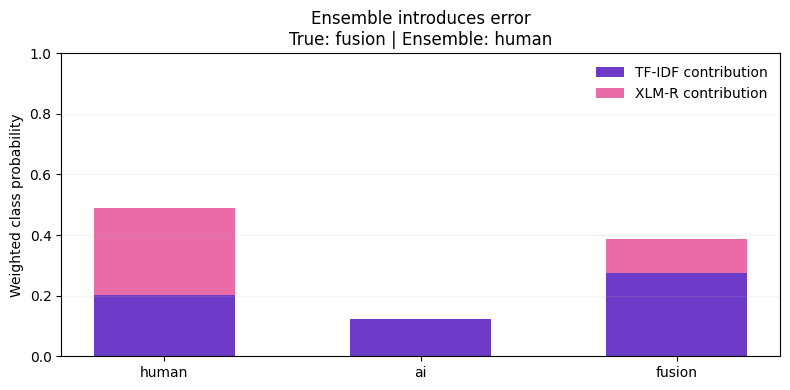

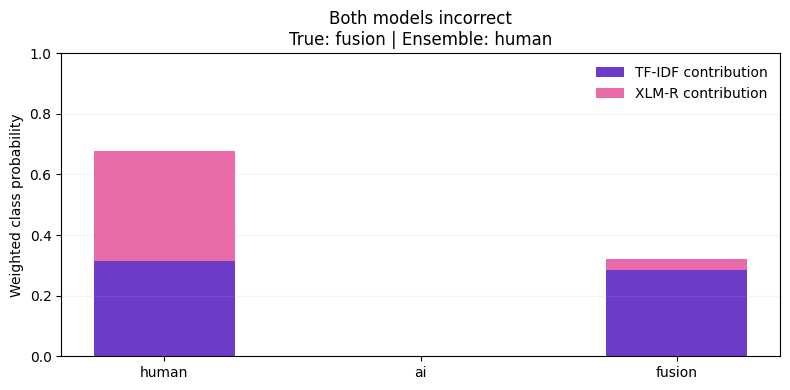

Local ensemble contribution analysis: PASSED


In [9]:
import matplotlib.pyplot as plt

for case in selected_cases:
    idx = case["row_index"]

    components = np.vstack([
        0.60 * tfidf_probs[idx],
        0.40 * xlmr_probs[idx]
    ])

    fig, ax = plt.subplots(figsize=(8, 4))

    x = np.arange(len(CLASS_ORDER))
    bottom = np.zeros(len(CLASS_ORDER))

    for component, label, color in zip(
        components,
        ["TF-IDF contribution", "XLM-R contribution"],
        ["#6C3CC8", "#E96BA8"]
    ):
        ax.bar(
            x,
            component,
            bottom=bottom,
            label=label,
            color=color,
            width=0.55
        )
        bottom += component

    ax.set_xticks(x)
    ax.set_xticklabels(CLASS_ORDER)
    ax.set_ylim(0, 1)
    ax.set_ylabel("Weighted class probability")

    ax.set_title(
        f"{case['case']}\n"
        f"True: {case['true_label']} | "
        f"Ensemble: {case['ensemble_prediction']}"
    )

    ax.legend(frameon=False)
    ax.grid(axis="y", alpha=0.15)

    plt.tight_layout()
    plt.show()

print("Local ensemble contribution analysis: PASSED")


## 4. Domain and language sensitivity analysis

I examine whether model performance and error correction vary across languages and document domains.

The exploratory analysis revealed substantial class-distribution differences between domains, which raises the possibility that the classifiers learn domain-specific patterns in addition to authorship-related signals.

I compare the TF-IDF model, XLM-RoBERTa, and the final ensemble within each language and domain using macro-F1.

I also measure how often the ensemble corrects or introduces errors relative to TF-IDF.

Differences in performance across domains do not, by themselves, establish shortcut learning. They indicate where additional explanation and robustness analysis may be useful.


In [10]:
import pandas as pd
import numpy as np
from pathlib import Path

TRAIN_PATH = Path("/content/hw3_data/train.csv")

assert TRAIN_PATH.exists(), (
    "train.csv is unavailable. Restore the competition "
    "data before running this cell."
)

metadata_df = pd.read_csv(
    TRAIN_PATH,
    usecols=["id", "lang", "domain"],
    dtype={"id": str, "lang": "category", "domain": "category"}
)

assert metadata_df["id"].is_unique

explain_metadata = explain_df[["id"]].merge(
    metadata_df,
    on="id",
    how="left",
    validate="one_to_one",
    sort=False
)

assert len(explain_metadata) == 55_031
assert explain_metadata[["lang", "domain"]].notna().all().all()

print("Validation documents:", len(explain_metadata))
print("Languages:", explain_metadata["lang"].nunique())
print("Domains:", explain_metadata["domain"].nunique())
print("Metadata alignment: PASSED")

Validation documents: 55031
Languages: 2
Domains: 8
Metadata alignment: PASSED


In [11]:
from sklearn.metrics import f1_score
from IPython.display import display

def evaluate_metadata_groups(column):
    rows = []

    for group_name, group_indices in explain_metadata.groupby(
        column,
        observed=True
    ).indices.items():

        indices = np.asarray(group_indices)

        row = {
            column: str(group_name),
            "documents": len(indices)
        }

        for name, predictions in model_predictions.items():
            row[name] = f1_score(
                y_true[indices],
                predictions[indices],
                labels=CLASS_ORDER,
                average="macro",
                zero_division=0
            )

        tfidf_correct_group = tfidf_pred[indices] == y_true[indices]
        ensemble_correct_group = ensemble_pred[indices] == y_true[indices]

        row["errors_fixed"] = int(
            (~tfidf_correct_group & ensemble_correct_group).sum()
        )
        row["errors_introduced"] = int(
            (tfidf_correct_group & ~ensemble_correct_group).sum()
        )

        rows.append(row)

    result = pd.DataFrame(rows)

    result["net_corrections"] = (
        result["errors_fixed"] - result["errors_introduced"]
    )

    return result.sort_values(
        "documents",
        ascending=False
    ).reset_index(drop=True)

language_results = evaluate_metadata_groups("lang")
domain_results = evaluate_metadata_groups("domain")

print("Performance by language:")
display(language_results.round(4))

print("\nPerformance by domain:")
display(domain_results.round(4))

language_results.to_csv(
    PROJECT_DIR / "xai_language_analysis.csv",
    index=False
)

domain_results.to_csv(
    PROJECT_DIR / "xai_domain_analysis.csv",
    index=False
)

print("\nDomain and language analysis: PASSED")

Performance by language:


,lang,documents,TF-IDF,XLM-R head-tail,Ensemble 60/40,errors_fixed,errors_introduced,net_corrections
0,en-EN,44420,0.8674,0.8759,0.9104,2408,811,1597
1,de-DE,10611,0.9200,0.8649,0.9365,386,220,166



Performance by domain:


,domain,documents,TF-IDF,XLM-R head-tail,Ensemble 60/40,errors_fixed,errors_introduced,net_corrections
0,student_essays,10942,0.9037,0.9107,0.9260,363,138,225
1,bundestag,10529,0.9204,0.8649,0.9367,384,220,164
2,cnn_news,8987,0.8625,0.9309,0.9433,714,124,590
3,blog_authorship_corpus,8053,0.7417,0.8268,0.8222,892,295,597
4,house_of_commons,6555,0.8938,0.8902,0.9268,265,87,178
5,euro_court_cases,5531,0.9303,0.8229,0.9338,142,117,25
6,arxiv_papers,2979,0.9046,0.5776,0.7843,13,37,-24
7,gutenberg,1455,0.7783,0.7872,0.8113,21,13,8



Domain and language analysis: PASSED



## 5. Feature-level explainability with an auxiliary linear model

I train a compact auxiliary TF-IDF classifier to investigate lexical features associated with the three authorship classes.

I select a deterministic subset exclusively from the original training folds, without using validation examples for model fitting. I limit the vocabulary size to keep memory requirements manageable.

I use the auxiliary model to study global feature importance and, subsequently, local word-level explanations with LIME.

The auxiliary classifier is not the final ensemble. Its feature explanations are exploratory and should not be interpreted as exact token attributions for XLM-RoBERTa or the combined model.


In [12]:
import gc
import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm

TRAIN_PATH = Path("/content/hw3_data/train.csv")
FOLDS_PATH = PROJECT_DIR / "cv_folds_v1.csv"

assert TRAIN_PATH.exists()
assert FOLDS_PATH.exists()

folds = pd.read_csv(
    FOLDS_PATH,
    usecols=["id", "cv_fold"],
    dtype={"id": str}
)

training_ids = set(
    folds.loc[folds["cv_fold"] != 0, "id"]
)

del folds
gc.collect()

sample_parts = []

for chunk in tqdm(
    pd.read_csv(
        TRAIN_PATH,
        usecols=["id", "text", "label"],
        dtype={"id": str, "label": str},
        chunksize=10_000
    ),
    desc="Sampling training documents"
):
    chunk = chunk.loc[
        chunk["id"].isin(training_ids)
    ]

    hashes = pd.util.hash_pandas_object(
        chunk["id"],
        index=False
    ).to_numpy(dtype=np.uint64)

    chunk = chunk.loc[(hashes % 1000) < 140]

    sample_parts.append(chunk)

aux_train_df = pd.concat(
    sample_parts,
    ignore_index=True
)

del sample_parts, training_ids
gc.collect()

assert aux_train_df["id"].is_unique
assert aux_train_df["label"].isin(CLASS_ORDER).all()
assert len(aux_train_df) > 20_000

print("Auxiliary training documents:", len(aux_train_df))
print("\nClass distribution:")
display(aux_train_df["label"].value_counts())

print("\nMemory-efficient training sample: PASSED")

Sampling training documents: 0it [00:00, ?it/s]

Auxiliary training documents: 30506

Class distribution:


,count
label,
ai,13727
fusion,9307
human,7472



Memory-efficient training sample: PASSED


In [13]:
import joblib
import time
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier

AUX_MODEL_PATH = (
    PROJECT_DIR / "xai_auxiliary_tfidf_model.joblib"
)

if AUX_MODEL_PATH.exists():
    auxiliary_model = joblib.load(AUX_MODEL_PATH)
    print("Loaded cached auxiliary model.")
else:
    auxiliary_model = Pipeline([
        ("tfidf", TfidfVectorizer(
            analyzer="word",
            ngram_range=(1, 2),
            max_features=30_000,
            min_df=3,
            sublinear_tf=True,
            dtype=np.float32
        )),
        ("classifier", SGDClassifier(
            loss="log_loss",
            alpha=1e-5,
            max_iter=30,
            tol=1e-3,
            random_state=SEED
        ))
    ])

    start_time = time.perf_counter()

    auxiliary_model.fit(
        aux_train_df["text"],
        aux_train_df["label"]
    )

    print(
        "Training time:",
        round(time.perf_counter() - start_time, 1),
        "seconds"
    )

    joblib.dump(
        auxiliary_model,
        AUX_MODEL_PATH,
        compress=3
    )

print(
    "Vocabulary size:",
    len(auxiliary_model.named_steps["tfidf"].vocabulary_)
)
print(
    "Classes:",
    auxiliary_model.named_steps["classifier"].classes_
)
print("Saved model:", AUX_MODEL_PATH)
print("Auxiliary model training: PASSED")

Training time: 57.5 seconds
Vocabulary size: 30000
Classes: ['ai' 'fusion' 'human']
Saved model: /content/drive/MyDrive/UCU_AI_HW3/xai_auxiliary_tfidf_model.joblib
Auxiliary model training: PASSED



## 6. Global feature importance

I analyze the learned coefficients of the auxiliary TF-IDF classifier to identify lexical features associated with each authorship class.

For each class, I examine the strongest positive and negative coefficients and visualize the most influential n-grams.

Since the classifier is linear, a feature's contribution to a class decision score is proportional to its TF-IDF value multiplied by its learned coefficient.

The coefficients explain the auxiliary classifier, not the original full-data TF-IDF baseline or XLM-RoBERTa. Large coefficients may reflect dataset-specific vocabulary, language differences, or domain-related shortcuts rather than genuine authorship characteristics.


In [14]:
import numpy as np
import pandas as pd
from IPython.display import display

vectorizer = auxiliary_model.named_steps["tfidf"]
classifier = auxiliary_model.named_steps["classifier"]

feature_names = vectorizer.get_feature_names_out()
coefficients = classifier.coef_
model_classes = classifier.classes_

assert coefficients.shape == (
    len(model_classes),
    len(feature_names)
)

TOP_K = 20
importance_rows = []

for class_idx, class_name in enumerate(model_classes):

    class_coef = coefficients[class_idx]

    positive_indices = np.argsort(class_coef)[-TOP_K:][::-1]
    negative_indices = np.argsort(class_coef)[:TOP_K]

    for rank, feature_idx in enumerate(positive_indices, 1):
        importance_rows.append({
            "class": class_name,
            "direction": "positive",
            "rank": rank,
            "feature": feature_names[feature_idx],
            "coefficient": float(class_coef[feature_idx])
        })

    for rank, feature_idx in enumerate(negative_indices, 1):
        importance_rows.append({
            "class": class_name,
            "direction": "negative",
            "rank": rank,
            "feature": feature_names[feature_idx],
            "coefficient": float(class_coef[feature_idx])
        })

feature_importance_df = pd.DataFrame(importance_rows)

for class_name in CLASS_ORDER:

    print(f"\nCLASS: {class_name.upper()}")

    class_features = feature_importance_df[
        feature_importance_df["class"] == class_name
    ]

    positive = class_features[
        class_features["direction"] == "positive"
    ][["feature", "coefficient"]]

    negative = class_features[
        class_features["direction"] == "negative"
    ][["feature", "coefficient"]]

    print("Strongest positive features:")
    display(positive.head(10).round(4))

    print("Strongest negative features:")
    display(negative.head(10).round(4))

IMPORTANCE_PATH = (
    PROJECT_DIR / "xai_global_feature_importance.csv"
)

feature_importance_df.to_csv(
    IMPORTANCE_PATH,
    index=False
)

print("\nSaved feature importance:", IMPORTANCE_PATH)
print("Global feature extraction: PASSED")


CLASS: HUMAN
Strongest positive features:


,feature,coefficient
80,dank,9.1109
81,vielen dank,6.4632
82,urllink,6.3117
83,in conclusion,5.4663
84,herzlichen dank,5.0369
85,vielen,4.8613
86,conclusion,4.6355
87,danke,4.5617
88,herzlichen,4.4877
89,student_name,4.2613


Strongest negative features:


,feature,coefficient
100,furthermore,-6.7619
101,this,-6.5630
102,me know,-6.2091
103,crucial,-6.2001
104,potential,-6.0733
105,these,-6.0398
106,herausforderungen,-5.9793
107,let me,-5.8513
108,wir müssen,-5.6852
109,missing,-5.5339



CLASS: AI
Strongest positive features:


,feature,coefficient
0,just,6.2215
1,let,5.7506
2,this,5.2764
3,it like,5.1109
4,like,4.9593
5,seriously,4.9256
6,maybe,4.5438
7,super,4.4858
8,honestly,4.4789
9,hey,4.4372


... (3 outputs left out)

,feature,coefficient
40,furthermore,10.2395
41,the,8.7757
42,and,7.9186
43,additionally,7.2650
44,missing part,6.9296
45,me know,6.6930
46,missing,6.4056
47,moreover,6.2880
48,missing section,5.3889
49,section,5.1539


Strongest negative features:


,feature,coefficient
60,conclusion,-10.1106
61,dank,-10.1066
62,in conclusion,-9.7959
63,vielen dank,-8.4400
64,kollegen heute,-5.6449
65,herzlichen dank,-5.4878
66,aufmerksamkeit,-5.3503
67,herzlichen,-4.9586
68,student_name,-4.7733
69,dr,-4.6899



Saved feature importance: /content/drive/MyDrive/UCU_AI_HW3/xai_global_feature_importance.csv
Global feature extraction: PASSED


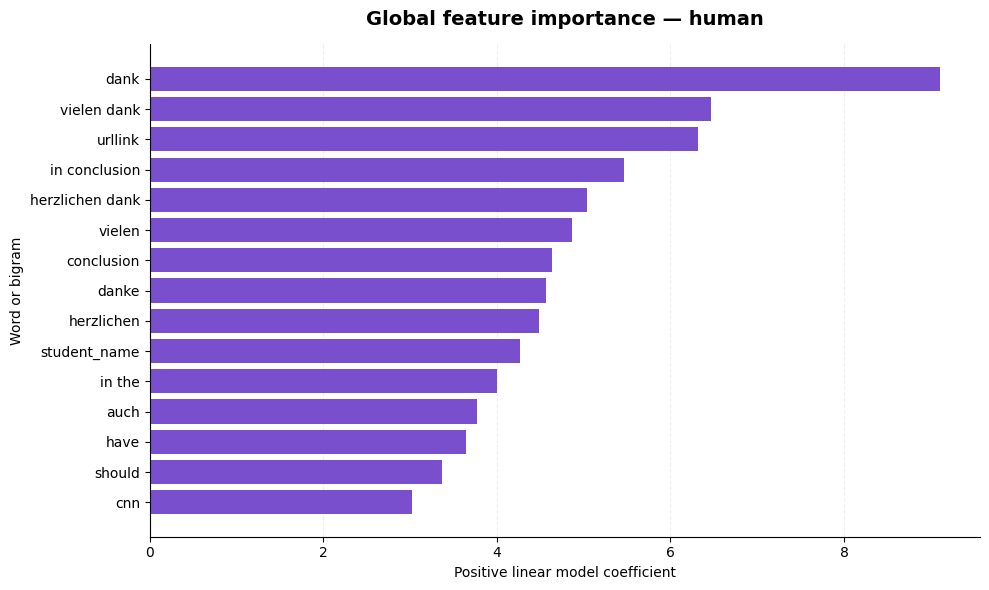

Saved: xai_global_features_human.png


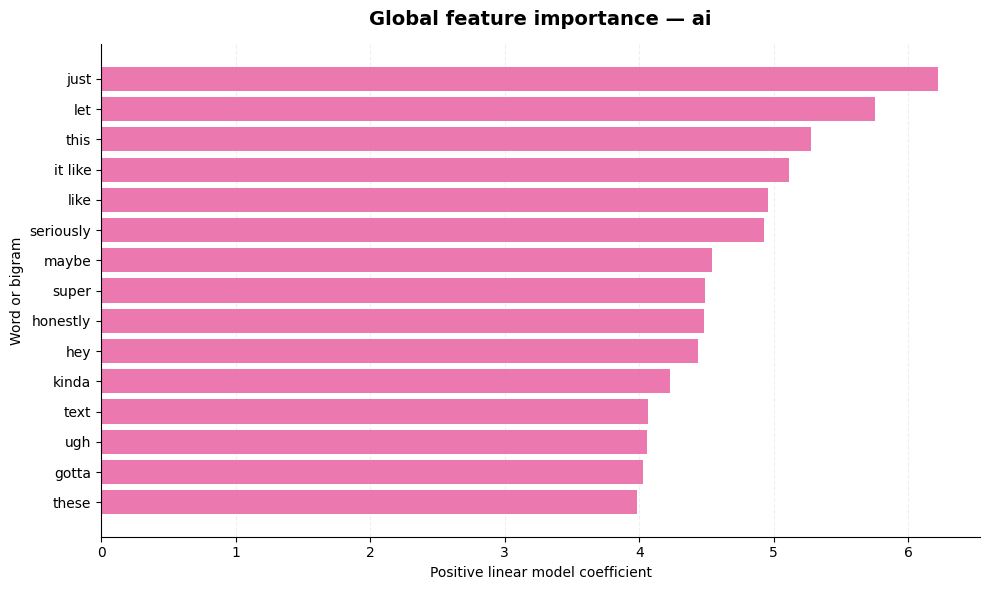

Saved: xai_global_features_ai.png


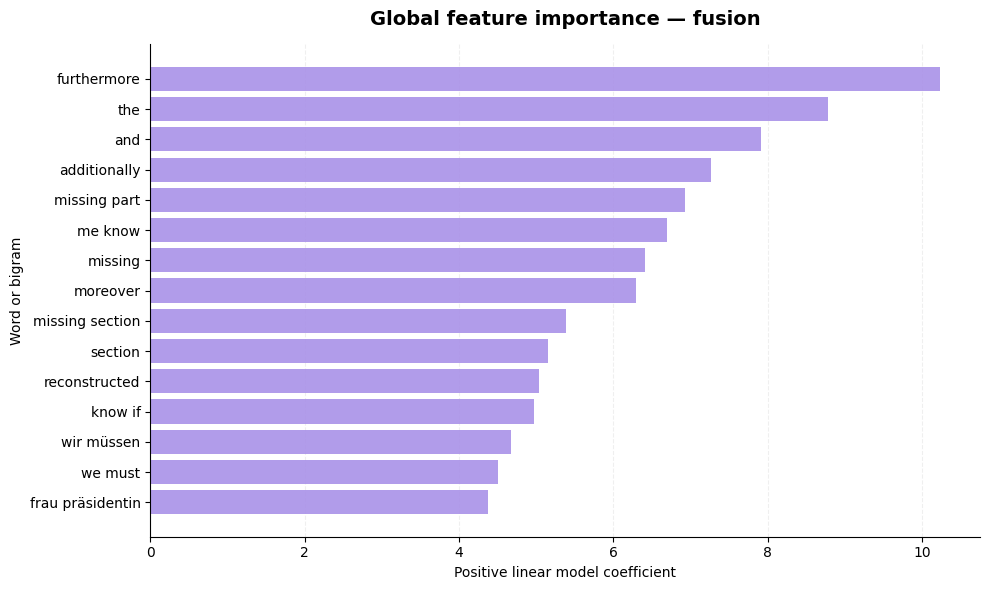

Saved: xai_global_features_fusion.png

Global feature visualizations: PASSED


In [15]:
import matplotlib.pyplot as plt

TOP_PLOT = 15

for class_name in CLASS_ORDER:

    top_features = (
        feature_importance_df[
            (feature_importance_df["class"] == class_name)
            & (feature_importance_df["direction"] == "positive")
        ]
        .sort_values("coefficient", ascending=False)
        .head(TOP_PLOT)
        .iloc[::-1]
    )

    fig, ax = plt.subplots(figsize=(10, 6))

    bars = ax.barh(
        top_features["feature"],
        top_features["coefficient"],
        color=CLASS_COLORS[class_name],
        alpha=0.9
    )

    ax.set_title(
        f"Global feature importance — {class_name}",
        fontsize=14,
        fontweight="bold",
        pad=14
    )

    ax.set_xlabel("Positive linear model coefficient")
    ax.set_ylabel("Word or bigram")

    ax.grid(axis="x", alpha=0.2, linestyle="--")
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()

    output_path = (
        PROJECT_DIR / f"xai_global_features_{class_name}.png"
    )

    plt.savefig(
        output_path,
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", output_path.name)

print("\nGlobal feature visualizations: PASSED")


## 7. Local feature explanations with LIME

I use LIME to explain individual predictions of the auxiliary TF-IDF classifier.

I select validation examples representing different outcomes of the final ensemble, together with a document from the ArXiv domain, where the final ensemble showed weaker performance.

For each example, LIME perturbs the input text and fits a locally interpretable surrogate model. I examine which words support or oppose the auxiliary classifier's predicted class.

These are approximate local explanations of the auxiliary classifier, not direct token attributions for the final TF-IDF/XLM-R ensemble.

I also inspect the local surrogate's fidelity to avoid treating unstable explanations as reliable evidence.


In [16]:
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

TRAIN_PATH = Path("/content/hw3_data/train.csv")

lime_cases = selected_cases_df[
    ["case", "id", "true_label"]
].copy()

arxiv_candidates = explain_metadata.loc[
    explain_metadata["domain"].astype(str) == "arxiv_papers",
    "id"
]

assert len(arxiv_candidates) > 0

arxiv_id = str(arxiv_candidates.iloc[0])

if arxiv_id not in set(lime_cases["id"]):
    arxiv_idx = int(
        np.flatnonzero(explain_df["id"].to_numpy() == arxiv_id)[0]
    )

    lime_cases = pd.concat([
        lime_cases,
        pd.DataFrame([{
            "case": "ArXiv domain example",
            "id": arxiv_id,
            "true_label": y_true[arxiv_idx]
        }])
    ], ignore_index=True)

selected_ids = set(lime_cases["id"])
text_parts = []

for chunk in pd.read_csv(
    TRAIN_PATH,
    usecols=["id", "text"],
    dtype={"id": str},
    chunksize=10_000
):
    matches = chunk.loc[chunk["id"].isin(selected_ids)]

    if not matches.empty:
        text_parts.append(matches)

    if sum(len(part) for part in text_parts) == len(selected_ids):
        break

selected_texts = pd.concat(
    text_parts,
    ignore_index=True
)

lime_cases = lime_cases.merge(
    selected_texts,
    on="id",
    how="left",
    validate="one_to_one"
)

assert lime_cases["text"].notna().all()
assert lime_cases["id"].is_unique

lime_cases["text_length"] = (
    lime_cases["text"].str.len()
)

display(
    lime_cases[
        ["case", "id", "true_label", "text_length"]
    ]
)

print("Selected validation cases:", len(lime_cases))
print("LIME input preparation: PASSED")

,case,id,true_label,text_length
0,Ensemble fixes TF-IDF,768deb,fusion,5494
1,Ensemble fixes XLM-R,ef2c3d,ai,6262
2,Ensemble introduces error,f4c3f0,fusion,646
3,Both models incorrect,8c4c79,fusion,1667
4,ArXiv domain example,06a296,ai,6071


Selected validation cases: 5
LIME input preparation: PASSED


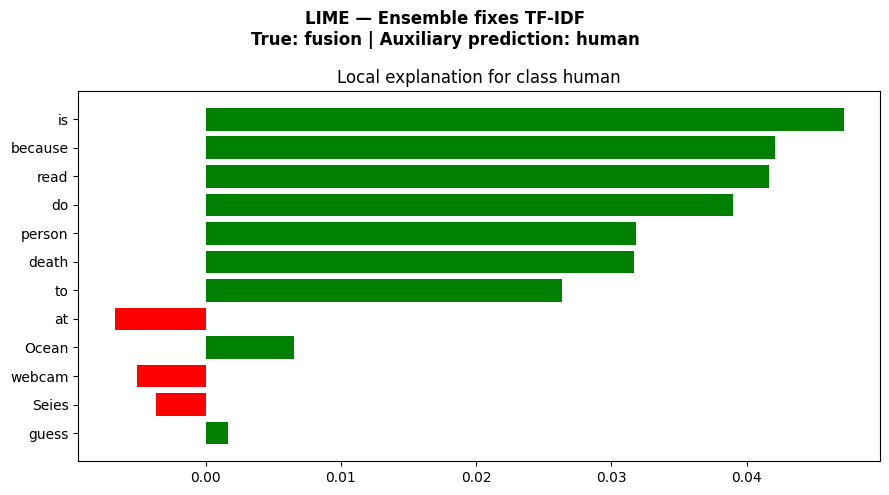

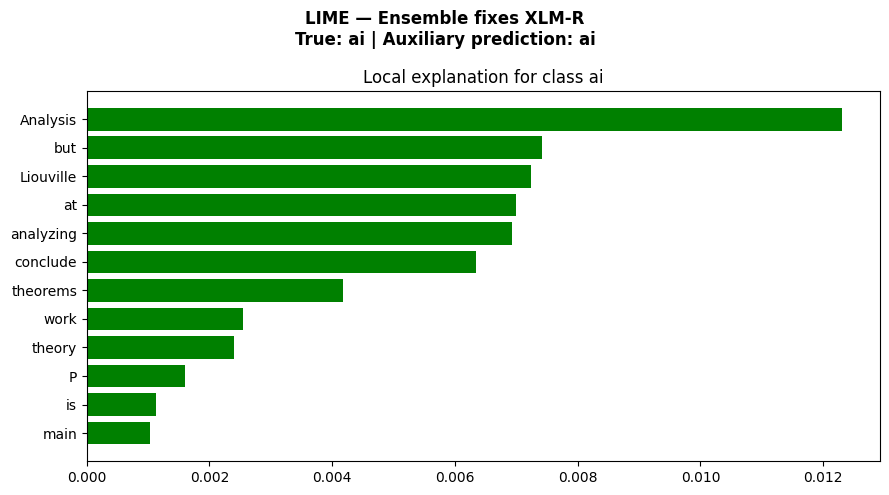

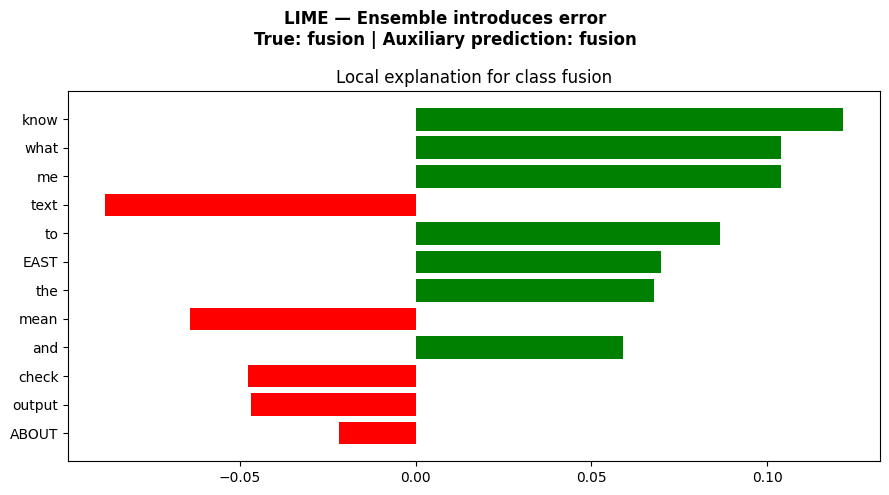

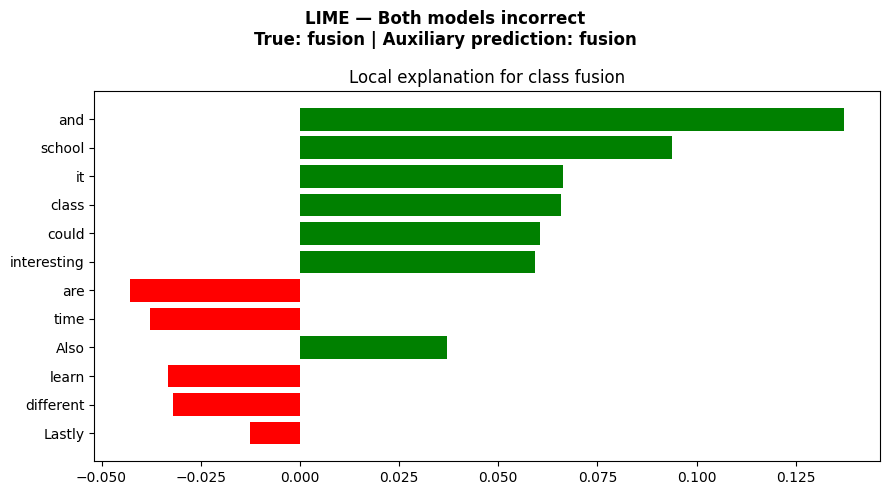

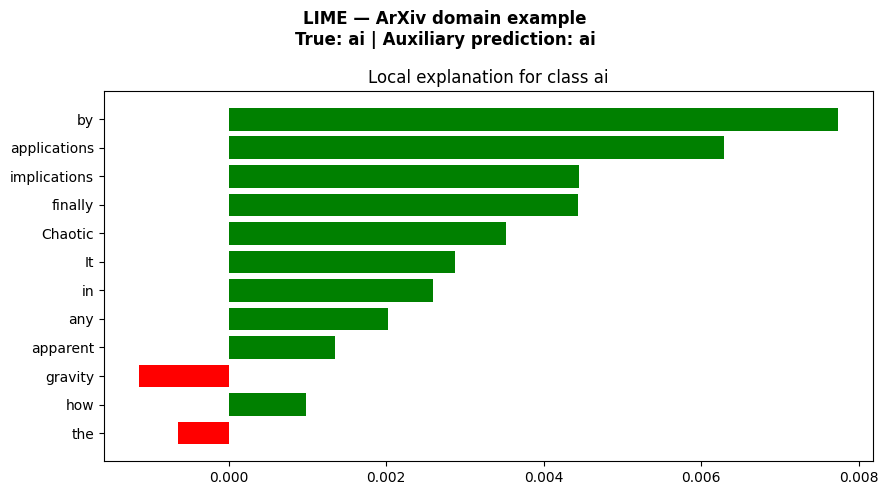

LIME explanation summary:


,case,id,true_label,auxiliary_prediction,confidence,lime_local_r2
0,Ensemble fixes TF-IDF,768deb,fusion,human,0.8321,0.3852
1,Ensemble fixes XLM-R,ef2c3d,ai,ai,0.9768,0.2706
2,Ensemble introduces error,f4c3f0,fusion,fusion,0.5865,0.6810
3,Both models incorrect,8c4c79,fusion,fusion,0.7149,0.6554
4,ArXiv domain example,06a296,ai,ai,0.9873,0.2039



LIME explanations: PASSED


In [17]:
import sys
import subprocess
import importlib.util

if importlib.util.find_spec("lime") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip",
        "install", "-q", "lime"
    ])

from lime.lime_text import LimeTextExplainer

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

auxiliary_classes = list(
    auxiliary_model.named_steps["classifier"].classes_
)

lime_explainer = LimeTextExplainer(
    class_names=auxiliary_classes,
    random_state=SEED,
    bow=True
)

lime_rows = []
lime_summary_rows = []

for _, case in lime_cases.iterrows():

    text = str(case["text"])

    probabilities = auxiliary_model.predict_proba(
        [text]
    )[0]

    predicted_index = int(np.argmax(probabilities))
    predicted_class = auxiliary_classes[predicted_index]

    explanation = lime_explainer.explain_instance(
        text,
        auxiliary_model.predict_proba,
        labels=(predicted_index,),
        num_features=12,
        num_samples=250
    )

    local_features = explanation.as_list(
        label=predicted_index
    )

    lime_summary_rows.append({
        "case": case["case"],
        "id": case["id"],
        "true_label": case["true_label"],
        "auxiliary_prediction": predicted_class,
        "confidence": float(
            probabilities[predicted_index]
        ),
        "lime_local_r2": float(explanation.score)
    })

    for rank, (feature, weight) in enumerate(
        local_features, start=1
    ):
        lime_rows.append({
            "case": case["case"],
            "id": case["id"],
            "predicted_class": predicted_class,
            "rank": rank,
            "feature": feature,
            "lime_weight": float(weight)
        })

    fig = explanation.as_pyplot_figure(
        label=predicted_index
    )

    fig.set_size_inches(9, 5)

    fig.suptitle(
        f"LIME — {case['case']}\n"
        f"True: {case['true_label']} | "
        f"Auxiliary prediction: {predicted_class}",
        fontsize=12,
        fontweight="bold"
    )

    plt.tight_layout()

    safe_name = str(case["case"]).lower().replace(
        " ", "_"
    ).replace("-", "_")

    plt.savefig(
        PROJECT_DIR / f"xai_lime_{safe_name}.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

lime_summary_df = pd.DataFrame(lime_summary_rows)
lime_features_df = pd.DataFrame(lime_rows)

print("LIME explanation summary:")
display(lime_summary_df.round(4))

lime_summary_df.to_csv(
    PROJECT_DIR / "xai_lime_summary.csv",
    index=False
)

lime_features_df.to_csv(
    PROJECT_DIR / "xai_lime_feature_weights.csv",
    index=False
)

print("\nLIME explanations: PASSED")


## 8. LIME reliability and stability analysis

I investigate the reliability of LIME explanations for two validation documents with low local surrogate fidelity.

I increase the number of perturbation samples and repeat each explanation with different random seeds.

I compare local R² scores and the overlap between the highest-ranked explanatory features.

This analysis helps distinguish potentially stable lexical explanations from artifacts of LIME's sampling procedure.

A higher R² or stronger feature overlap does not establish causal attribution or guarantee that the explanation generalizes beyond the local perturbation neighborhood.


In [18]:
from lime.lime_text import LimeTextExplainer

import numpy as np
import pandas as pd
from IPython.display import display

RECHECK_CASES = [
    "Ensemble fixes XLM-R",
    "ArXiv domain example"
]

stability_rows = []
feature_sets = {}

for case_name in RECHECK_CASES:

    case_row = lime_cases.loc[
        lime_cases["case"] == case_name
    ].iloc[0]

    text = str(case_row["text"])

    probabilities = auxiliary_model.predict_proba([text])[0]
    predicted_idx = int(np.argmax(probabilities))

    for seed in [42, 123]:

        explainer = LimeTextExplainer(
            class_names=auxiliary_classes,
            random_state=seed,
            bow=True
        )

        explanation = explainer.explain_instance(
            text,
            auxiliary_model.predict_proba,
            labels=(predicted_idx,),
            num_features=12,
            num_samples=1500
        )

        local_features = explanation.as_list(
            label=predicted_idx
        )

        top_five = {
            feature
            for feature, weight in sorted(
                local_features,
                key=lambda item: abs(item[1]),
                reverse=True
            )[:5]
        }

        feature_sets[(case_name, seed)] = top_five

        stability_rows.append({
            "case": case_name,
            "seed": seed,
            "num_samples": 1500,
            "lime_local_r2": float(explanation.score),
            "top_features": ", ".join(
                feature for feature, _ in local_features[:5]
            )
        })

stability_df = pd.DataFrame(stability_rows)

print("LIME reliability results:")
display(stability_df.round(4))

print("\nTop-5 feature stability:")

overlap_rows = []

for case_name in RECHECK_CASES:

    first = feature_sets[(case_name, 42)]
    second = feature_sets[(case_name, 123)]

    jaccard = len(first & second) / len(first | second)

    overlap_rows.append({
        "case": case_name,
        "top5_jaccard": jaccard,
        "shared_features": ", ".join(sorted(first & second))
    })

overlap_df = pd.DataFrame(overlap_rows)

display(overlap_df.round(4))

stability_df.to_csv(
    PROJECT_DIR / "xai_lime_reliability.csv",
    index=False
)

overlap_df.to_csv(
    PROJECT_DIR / "xai_lime_stability.csv",
    index=False
)

print("\nLIME reliability analysis: PASSED")

LIME reliability results:


,case,seed,num_samples,lime_local_r2,top_features
0,Ensemble fixes XLM-R,42,1500,0.4269,"complex, text, recent, these, attention"
1,Ensemble fixes XLM-R,123,1500,0.4550,"text, complex, paper, explore, conditions"
2,ArXiv domain example,42,1500,0.3642,"characterized, specific, within, complex, dyna..."
3,ArXiv domain example,123,1500,0.3950,"characterized, realm, within, complex, chaos"



Top-5 feature stability:


,case,top5_jaccard,shared_features
0,Ensemble fixes XLM-R,0.2500,"complex, text"
1,ArXiv domain example,0.4286,"characterized, complex, within"



LIME reliability analysis: PASSED



## 9. Findings and limitations

### Main findings

**1. Complementary model behavior**

The final 60% TF-IDF / 40% XLM-RoBERTa ensemble achieved 0.91596 macro-F1 on the complete validation fold, compared with 0.87852 for TF-IDF and 0.87345 for XLM-RoBERTa.

The ensemble corrected 2,794 TF-IDF errors while introducing 1,031 new errors. The largest net improvement occurred for the `fusion` class.

**2. Uneven performance across domains**

The ensemble improved performance in most domains, but its macro-F1 on `arxiv_papers` was 0.7843, compared with 0.9046 for TF-IDF alone. This demonstrates that ensemble improvements are not uniform across domains.

**3. Potential lexical shortcuts**

The auxiliary classifier assigned large coefficients to features such as `vielen dank`, `student_name`, `furthermore`, and `missing section`.

These features may reflect domain vocabulary, formatting conventions, or dataset construction artifacts rather than generalizable authorship characteristics.

**4. Local explanation reliability**

LIME explanations showed varying local fidelity. Increasing perturbation samples improved local R² for the two reexamined documents, but the top-five feature sets remained sensitive to random seeds.

### Limitations

- Global feature importance and LIME explain an auxiliary classifier trained on 30,506 documents, not the original full-data baseline or the final ensemble.
- The ensemble probability analysis explains model contributions, not token-level causality.
- LIME explanations depend on the perturbation procedure and may be unstable for individual documents.
- Domain-level performance differences and lexical associations do not establish causal shortcut learning.
- The selected local examples illustrate specific cases and are not representative of all validation documents.

### Conclusion

Combining lexical and contextual models substantially improved classification performance, especially for the challenging `fusion` class. However, the explainability analysis revealed domain-dependent weaknesses, potential dataset-specific lexical signals, and limitations in the stability of local explanations.

These findings suggest that model predictions should be interpreted alongside domain information and explanation reliability, rather than relying solely on confidence scores.


In [19]:
from pathlib import Path
import pandas as pd
from IPython.display import display

required_artifacts = [
    "xai_language_analysis.csv",
    "xai_domain_analysis.csv",
    "xai_auxiliary_tfidf_model.joblib",
    "xai_global_feature_importance.csv",
    "xai_global_features_human.png",
    "xai_global_features_ai.png",
    "xai_global_features_fusion.png",
    "xai_lime_summary.csv",
    "xai_lime_feature_weights.csv",
    "xai_lime_reliability.csv",
    "xai_lime_stability.csv",
]

artifact_status = pd.DataFrame([
    {
        "artifact": filename,
        "exists": (PROJECT_DIR / filename).is_file(),
        "size_mb": round(
            (PROJECT_DIR / filename).stat().st_size / 1024**2, 3
        ) if (PROJECT_DIR / filename).is_file() else 0
    }
    for filename in required_artifacts
])

display(artifact_status)

missing = artifact_status.loc[
    ~artifact_status["exists"], "artifact"
].tolist()

assert not missing, f"Missing artifacts: {missing}"

assert len(lime_summary_df) == 5
assert len(stability_df) == 4
assert len(overlap_df) == 2

print("\nAll explainability artifacts verified: PASSED")
print("Homework 3 — Explainability: COMPLETED")

,artifact,exists,size_mb
0,xai_language_analysis.csv,True,0.000
1,xai_domain_analysis.csv,True,0.001
2,xai_auxiliary_tfidf_model.joblib,True,0.666
3,xai_global_feature_importance.csv,True,0.005
4,xai_global_features_human.png,True,0.059
5,xai_global_features_ai.png,True,0.056
6,xai_global_features_fusion.png,True,0.069
7,xai_lime_summary.csv,True,0.000
8,xai_lime_feature_weights.csv,True,0.004
9,xai_lime_reliability.csv,True,0.000



All explainability artifacts verified: PASSED
Homework 3 — Explainability: COMPLETED
